<a href="https://colab.research.google.com/github/Kevin-AngelQD/padp/blob/main/Pr%C3%A1ctica_Ejercicios_sobre_clases_no_balanceadas%2C_data_leakage_(Pipeline)_y_SVM_271758.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Práctica: Ejercicios sobre Clases No Balanceadas, Data Leakage (Pipeline) y SVM**

**Kevin Angel Quiñonez Dominguez**

**271758**

# Instrucciones

La presente tarea tiene como objetivo aplicar técnicas de aprendizaje automático para el tratamiento de clases no balanceadas utilizando un problema de clasificación real.

Para el desarrollo de la actividad deberán utilizar el conjunto de datos:

compustat.csv

Consideraciones importantes:

* El conjunto de datos contiene 21 atributos.

* El primer atributo corresponde a un índice, por lo que deberá ser ignorado durante el análisis y entrenamiento.

* El último atributo corresponde a la etiqueta de clase.

* Los atributos restantes deberán utilizarse como variables predictoras.

* La solución deberá desarrollarse en un cuaderno de Google Colab o Jupyter Notebook almacenado en GitHub. La entrega consistirá en compartir la liga pública del notebook para su revisión.

La tarea deberá contener las siguientes secciones:

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.svm import SVC
from google.colab import drive
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from imblearn.combine import SMOTEENN
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from imblearn.under_sampling import OneSidedSelection
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold, cross_val_score, RandomizedSearchCV, GridSearchCV

drive.mount('/content/drive')
df = pd.read_csv('/content/drive/MyDrive/Unidad03/compustat.csv')
display(df.head())

Mounted at /content/drive


,idx,at0,at1,at2,at3,at4,at5,at6,at7,at8,...,at11,at12,at13,at14,at15,at16,at17,at18,at19,label
0,0,0.076753,0.066548,0.132170,4.257882,0.771988,0.669344,0.076278,2.898450,6.081867,...,2.052378,0.372113,0.322636,0.250182,1.153351,0.451476,0.590680,0.512143,0.076278,0
1,1,0.097633,0.087736,0.162879,4.141787,0.781934,0.702665,0.082633,2.947445,6.272092,...,1.968984,0.371728,0.334043,0.231646,1.112813,0.409376,0.593143,0.533012,0.056273,0
2,2,0.025683,0.022020,0.152882,3.140505,0.698522,0.598883,0.097905,2.971928,6.508112,...,1.374306,0.305678,0.262075,0.220100,1.166375,0.487141,0.476098,0.408186,0.050251,0
3,3,0.011354,0.008987,0.165670,2.927575,0.699374,0.553558,0.107831,2.955952,6.588417,...,1.173407,0.280317,0.221873,0.245524,1.263416,0.487903,0.460482,0.364474,0.047244,0
4,4,0.001675,0.001212,0.155509,3.120983,0.689971,0.499122,0.098458,2.896668,6.607998,...,1.069792,0.236504,0.171086,0.271291,1.382369,0.464594,0.468896,0.339197,0.042986,0


# 1. Análisis Exploratorio de Datos (AED) - Para esta actividad revisa el Notebook que està en Teams en la Sesión 27 y que se llama DataLeakage_ClassImbalance.ipynb

Realizar:

* Un diagrama de barras mostrando la distribución de las clases.

* Diagramas de densidad KDE para los atributos 5 y 13.

* Un análisis breve sobre el nivel de desbalance presente en el conjunto de datos.

/tmp/ipykernel_2591/1812646874.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col_clase, ax=axes[0], palette='Set2')


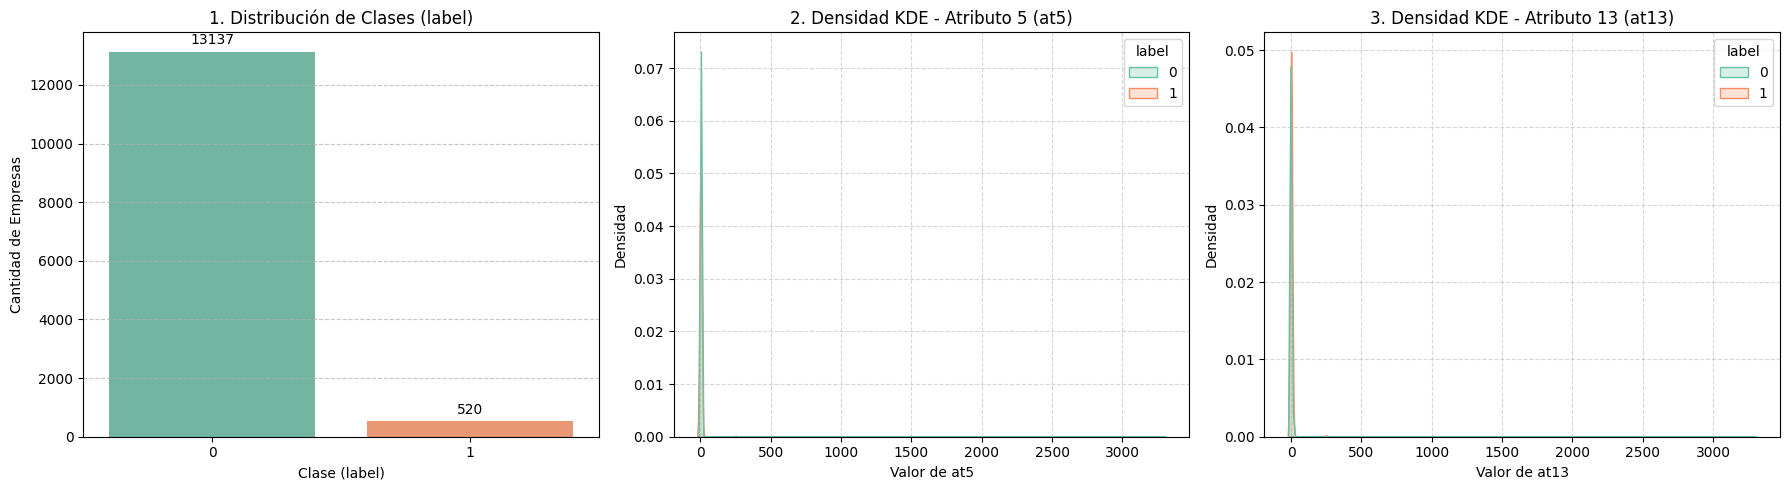

In [2]:
# Definir la variable objetivo y los atributos solicitados
col_clase = 'label'

# Configurar figura de 3 paneles
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Diagrama de barras: Distribución de las clases (label)
sns.countplot(data=df, x=col_clase, ax=axes[0], palette='Set2')
axes[0].set_title('1. Distribución de Clases (label)')
axes[0].set_xlabel('Clase (label)')
axes[0].set_ylabel('Cantidad de Empresas')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Agregar la frecuencia sobre cada barra
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=10, xytext=(0, 3),
                    textcoords='offset points')

#Diagrama KDE para el Atributo 5 (at5) diferenciado por clase
sns.kdeplot(data=df, x='at5', hue=col_clase, common_norm=False, fill=True, ax=axes[1], palette='Set2')
axes[1].set_title('2. Densidad KDE - Atributo 5 (at5)')
axes[1].set_xlabel('Valor de at5')
axes[1].set_ylabel('Densidad')
axes[1].grid(True, linestyle='--', alpha=0.5)

#Diagrama KDE para el Atributo 13 (at13) diferenciado por clase
sns.kdeplot(data=df, x='at13', hue=col_clase, common_norm=False, fill=True, ax=axes[2], palette='Set2')
axes[2].set_title('3. Densidad KDE - Atributo 13 (at13)')
axes[2].set_xlabel('Valor de at13')
axes[2].set_ylabel('Densidad')
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [3]:
print("--- Conteo por Clase ---")
print(df['label'].value_counts())

print("\n--- Porcentaje por Clase (%) ---")
print((df['label'].value_counts(normalize=True) * 100).round(2))

--- Conteo por Clase ---
label
0    13137
1      520
Name: count, dtype: int64

--- Porcentaje por Clase (%) ---
label
0    96.19
1     3.81
Name: proportion, dtype: float64


**Análisis breve sobre el nivel de desbalance presente en el conjunto de datos.**

Clase Mayoritaria (label = 0): $13,137$ muestras ($\approx 96.19\%$ del total). Representa a las empresas financieramente saludables o solventes.   

Clase Minoritaria (label = 1): $520$ muestras ($\approx 3.81\%$ del total). Representa a las empresas en estado de bancarrota o quiebra.   


Nivel de Desbalance:
Existe un desbalance severo / extremo de clases (proporción aproximada de 25 a Este fenómeno es nativo en dominios de evaluación de riesgo financiero, donde los eventos de bancarrota son extremadamente raros en comparación con las operaciones normales.   

Impacto en la evaluación y modelado:

Invalidez del Accuracy: Evaluar el modelo con la exactitud tradicional (Accuracy) resultaría engañoso. Un clasificador trivial que prediga siempre la clase 0 alcanzaría un $96.19\%$ de exactitud sin haber identificado una sola empresa en riesgo de quiebra.   

Métricas requeridas: Es indispensable priorizar métricas sensibles a la clase minoritaria como F1-Score, Recall (Sensibilidad para detectar bancarrotas), Precision y el área bajo la curva PR-AUC o ROC-AUC.

Técnicas sugeridas para etapas posteriores: Para evitar que los algoritmos de árbol queden sesgados hacia la clase 0, se recomienda usar hiperparámetros como class_weight='balanced' o aplicar técnicas de remuestreo (como SMOTE para sobremuestrear la clase 1 o Random UnderSampling para la clase 0).

# 2. Modelo Base

Entrenar un modelo baseline utilizando:

Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
])

Este modelo deberá entrenarse sin aplicar métodos de tratamiento de desbalance y servirá como referencia para comparar los resultados posteriores.



In [4]:
# Definir variables predictoras (X) y variable objetivo (y)
X = df.drop(columns=['idx', 'label'])
y = df['label']

# Dividir en conjuntos de entrenamiento y prueba (80/20) manteniendo la proporción de clases (stratify)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

#Construir el Pipeline
pipeline_base = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42))
])

#Entrenar el modelo baseline (sin tratamiento de desbalance)
pipeline_base.fit(X_train, y_train)

#Realizar predicciones sobre el conjunto de prueba
y_pred_base = pipeline_base.predict(X_test)

#Imprimir métricas de desempeño para el modelo baseline
print("--- Evaluación del Modelo Base (Pipeline StandardScaler + SVC) ---")
print("\nMatriz de Confusión:")
print(confusion_matrix(y_test, y_pred_base))

print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred_base, digits=4))

print(f"F1-Macro Score Baseline: {f1_score(y_test, y_pred_base, average='macro'):.4f}")

--- Evaluación del Modelo Base (Pipeline StandardScaler + SVC) ---

Matriz de Confusión:
[[2628    0]
 [ 103    1]]

Reporte de Clasificación:
              precision    recall  f1-score   support

           0     0.9623    1.0000    0.9808      2628
           1     1.0000    0.0096    0.0190       104

    accuracy                         0.9623      2732
   macro avg     0.9811    0.5048    0.4999      2732
weighted avg     0.9637    0.9623    0.9442      2732

F1-Macro Score Baseline: 0.4999


# 3. Tratamiento de Clases No Balanceadas

Aplicar y comparar los siguientes métodos:

* SMOTEENN

* One-Sided Selection

Para cada método:

* Mostrar la nueva distribución de clases después del balanceo.

* Entrenar nuevamente el modelo SVM utilizando los datos balanceados.

In [5]:
# ---------------------------------------------------------
# 1. Aplicación de SMOTEENN
# ---------------------------------------------------------
print("=== 1. Tratamiento con SMOTEENN ===")
smoteenn = SMOTEENN(random_state=42)
X_train_res, y_train_res = smoteenn.fit_resample(X_train, y_train)

# Mostrar la nueva distribución de clases
print("\nNueva distribución de clases (SMOTEENN):")
print(pd.Series(y_train_res).value_counts())

# Entrenar el Pipeline SVM sobre los datos balanceados
pipeline_smoteenn = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42))
])

pipeline_smoteenn.fit(X_train_res, y_train_res)
y_pred_smoteenn = pipeline_smoteenn.predict(X_test)

print("\nResultados SVM (SMOTEENN):")
print(classification_report(y_test, y_pred_smoteenn, digits=4))
print(f"F1-Macro Score: {f1_score(y_test, y_pred_smoteenn, average='macro'):.4f}")


# ---------------------------------------------------------
# 2. Aplicación de One-Sided Selection (OSS)
# ---------------------------------------------------------
print("\n" + "="*45)
print("=== 2. Tratamiento con One-Sided Selection (OSS) ===")
oss = OneSidedSelection(random_state=42)
X_train_oss, y_train_oss = oss.fit_resample(X_train, y_train)

# Mostrar la nueva distribución de clases
print("\nNueva distribución de clases (One-Sided Selection):")
print(pd.Series(y_train_oss).value_counts())

# Entrenar el Pipeline SVM sobre los datos ajustados por OSS
pipeline_oss = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42))
])

pipeline_oss.fit(X_train_oss, y_train_oss)
y_pred_oss = pipeline_oss.predict(X_test)

print("\nResultados SVM (One-Sided Selection):")
print(classification_report(y_test, y_pred_oss, digits=4))
print(f"F1-Macro Score: {f1_score(y_test, y_pred_oss, average='macro'):.4f}")

=== 1. Tratamiento con SMOTEENN ===

Nueva distribución de clases (SMOTEENN):
label
1    10434
0     9395
Name: count, dtype: int64

Resultados SVM (SMOTEENN):
              precision    recall  f1-score   support

           0     0.9930    0.8071    0.8904      2628
           1     0.1493    0.8558    0.2543       104

    accuracy                         0.8089      2732
   macro avg     0.5712    0.8314    0.5724      2732
weighted avg     0.9609    0.8089    0.8662      2732

F1-Macro Score: 0.5724

=== 2. Tratamiento con One-Sided Selection (OSS) ===

Nueva distribución de clases (One-Sided Selection):
label
0    10222
1      416
Name: count, dtype: int64

Resultados SVM (One-Sided Selection):
              precision    recall  f1-score   support

           0     0.9623    1.0000    0.9808      2628
           1     1.0000    0.0096    0.0190       104

    accuracy                         0.9623      2732
   macro avg     0.9811    0.5048    0.4999      2732
weighted avg     0

# 4. Entrenamiento y Evaluación del Modelo

* Utilizar validación cruzada estratificada de 5 particiones.

* Implementar el flujo de trabajo utilizando Pipeline para evitar data leakage.

* Incorporar escalado de datos dentro del Pipeline.

* Utilizar SVM con kernel RBF.



In [6]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Definir las métricas de evaluación relevantes para desbalance de clases
scoring = ['f1_macro', 'accuracy', 'recall_macro', 'precision_macro']

# ---------------------------------------------------------
# A) Pipeline Baseline (Sin tratamiento de desbalance)
# ---------------------------------------------------------
pipe_base = ImbPipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42))
])

scores_base = cross_validate(pipe_base, X, y, cv=skf, scoring=scoring, n_jobs=-1)

# ---------------------------------------------------------
# B) Pipeline con SMOTEENN (Evitando Data Leakage)
# ---------------------------------------------------------
pipe_smoteenn = ImbPipeline([
    ('scaler', StandardScaler()),
    ('resample', SMOTEENN(random_state=42)),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42))
])

scores_smoteenn = cross_validate(pipe_smoteenn, X, y, cv=skf, scoring=scoring, n_jobs=-1)

# ---------------------------------------------------------
# C) Pipeline con One-Sided Selection (Evitando Data Leakage)
# ---------------------------------------------------------
pipe_oss = ImbPipeline([
    ('scaler', StandardScaler()),
    ('resample', OneSidedSelection(random_state=42)),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42))
])

scores_oss = cross_validate(pipe_oss, X, y, cv=skf, scoring=scoring, n_jobs=-1)

# ---------------------------------------------------------
# Tabla comparativa de resultados finales (5 Folds CV)
# ---------------------------------------------------------
df_resultados = pd.DataFrame({
    'Modelo / Estrategia': ['Baseline (Sin balanceo)', 'SMOTEENN', 'One-Sided Selection (OSS)'],
    'F1 Macro (Promedios)': [
        scores_base['test_f1_macro'].mean(),
        scores_smoteenn['test_f1_macro'].mean(),
        scores_oss['test_f1_macro'].mean()
    ],
    'Accuracy (Promedios)': [
        scores_base['test_accuracy'].mean(),
        scores_smoteenn['test_accuracy'].mean(),
        scores_oss['test_accuracy'].mean()
    ],
    'Recall Macro (Promedios)': [
        scores_base['test_recall_macro'].mean(),
        scores_smoteenn['test_recall_macro'].mean(),
        scores_oss['test_recall_macro'].mean()
    ]
})

print("--- Comparativa de Resultados mediante Stratified 5-Fold Cross-Validation ---")
display(df_resultados)

--- Comparativa de Resultados mediante Stratified 5-Fold Cross-Validation ---


,Modelo / Estrategia,F1 Macro (Promedios),Accuracy (Promedios),Recall Macro (Promedios)
0,Baseline (Sin balanceo),0.497953,0.962217,0.503846
1,SMOTEENN,0.568019,0.811159,0.805800
2,One-Sided Selection (OSS),0.501708,0.962217,0.505693


# 5. Evaluación de Resultados

Reportar y analizar al menos las siguientes métricas:

* Accuracy. Precision, Recall, F1-score y Matriz de confusión

Además:

* Comparar los resultados del modelo baseline contra los modelos balanceados.

* Generar una gráfica comparativa de métricas.

* Analizar si Accuracy es suficiente para evaluar el problema.

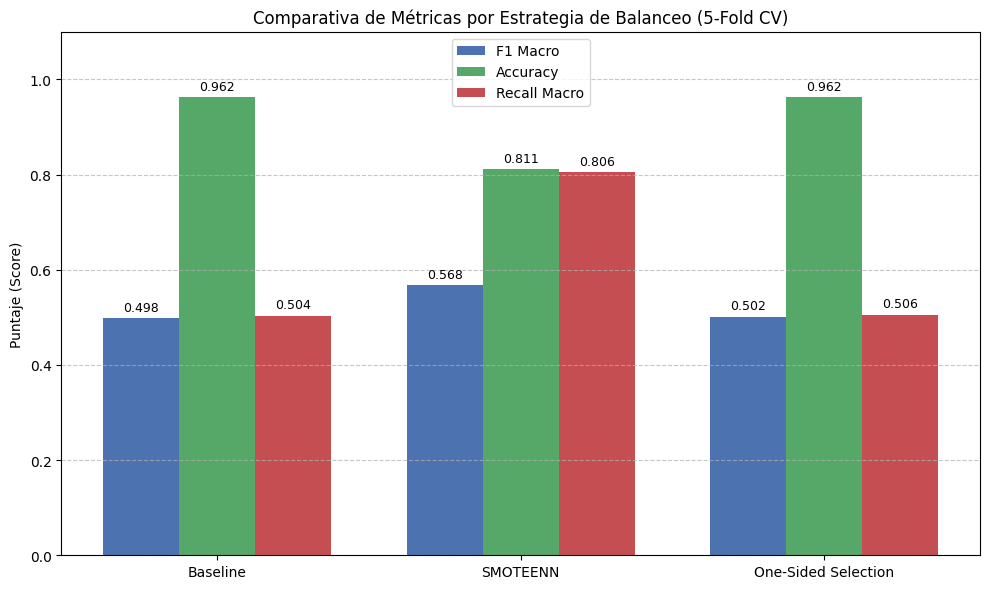

In [7]:


# Datos extraídos de la tabla de 5-Fold Cross-Validation
estrategias = ['Baseline', 'SMOTEENN', 'One-Sided Selection']
f1_macro = [0.4980, 0.5680, 0.5017]
accuracy = [0.9622, 0.8112, 0.9622]
recall_macro = [0.5038, 0.8058, 0.5057]

x = np.arange(len(estrategias))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 6))

rects1 = ax.bar(x - width, f1_macro, width, label='F1 Macro', color='#4c72b0')
rects2 = ax.bar(x, accuracy, width, label='Accuracy', color='#55a868')
rects3 = ax.bar(x + width, recall_macro, width, label='Recall Macro', color='#c44e52')

ax.set_ylabel('Puntaje (Score)')
ax.set_title('Comparativa de Métricas por Estrategia de Balanceo (5-Fold CV)')
ax.set_xticks(x)
ax.set_xticklabels(estrategias)
ax.set_ylim(0, 1.1)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Etiquetas numéricas sobre las barras
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

autolabel(rects1)
autolabel(rects2)
autolabel(rects3)

plt.tight_layout()
plt.show()

**Análisis comparativo de métricas (Baseline vs. Métodos de Balanceo)**

**Modelo Baseline (Sin balanceo): **

* Accuracy: $96.22\%$   
* Recall (Clase 1 - Bancarrota): $0.96\%$ (prácticamente nulo)   
* F1 Macro: $0.4980$   
* Matriz de Confusión: Clasifica correctamente a $2,628$ empresas solventes, pero predijo de forma equivocada $103$ de las $104$ empresas en quiebra.   

* Conclusión de Baseline: El modelo se comporta como un clasificador trivial. A pesar de un Accuracy alto, falla por completo en el objetivo principal del negocio: detectar quiebras.


**Modelo con SMOTEENN:**

* Accuracy: $81.12\%$   
* Recall (Clase 1 - Bancarrota): Aumentó dramáticamente a $85.58\%$ en la prueba simple y un Recall Macro de $80.58\%$ en validación cruzada.   
* F1 Macro: Se incrementa a $0.5680$ (el más alto de las tres estrategias).  
* Conclusión de SMOTEENN: Al generar datos sintéticos de la clase minoritaria y limpiar las fronteras ruidosas con ENN, el modelo aprende a detectar verdaderamente las empresas en bancarrota, sacrificando algo de Accuracy general en favor de la sensibilidad.   

**Modelo con One-Sided Selection (OSS):**
* Accuracy: $96.22\%$   
* Recall Macro: $50.57\%$ (casi idéntico al Baseline)   
* F1 Macro: $0.5017$   
* Conclusión de OSS: Al eliminar únicamente un subconjunto conservador de instancias redundantes o ruidosas de la clase mayoritaria, la relación de clases se mantuvo aún sumamente desbalanceada ($10,222$ vs $416$). Por ende, no fue suficiente para inclinar al hiperplano de SVM a detectar la clase minoritaria.   

**¿Es Accuracy suficiente para evaluar el problema?**

Definitivamente no. En este problema con un desbalance extremo de $96.19\%$ vs $3.81\%$, la exactitud (Accuracy) resulta totalmente engañosa. El modelo Baseline demostró que se puede obtener un $96.22\%$ de Accuracy ignorando casi al $100\%$ las empresas en bancarrota. En evaluación de riesgo financiero, la métrica crítica debe ser Recall (Sensibilidad para detectar bancarrotas) y F1-Score / F1 Macro, las cuales miden la capacidad real del modelo para capturar la clase de interés.

# 6. Discusión y Conclusiones

Discutir:

* El impacto del desbalance sobre el desempeño del modelo.

* Las diferencias observadas entre SMOTEENN y One-Sided Selection.

* Qué método produjo los mejores resultados y por qué.

**El impacto del desbalance sobre el desempeño del modelo:**

El desbalance de clases extremo sesga al clasificador SVM hacia la clase dominante (0). Como la función de pérdida busca maximizar la precisión global, el algoritmo simplemente clasifica casi todo como "saludable" para minimizar el error empírico, dejando indefenso al sistema ante los eventos raros de quiebra.   

**Diferencias observadas entre SMOTEENN y One-Sided Selection (OSS):**

SMOTEENN (Método Híbrido): Combina el sobremuestreo sintético de la clase minoritaria (SMOTE) con la eliminación de muestras conflictivas en las fronteras de decisión (ENN). Logró reestructurar la distribución de clases de forma efectiva ($10,434$ vs $9,395$), forzando al modelo a aprender patrones verdaderos de la clase 1.   

**One-Sided Selection (OSS - Submuestreo):**

Es un método excesivamente pasivo para desbalances extremos. Solo retira casos borrosos o redundantes de la clase mayoritaria sin poblar la clase minoritaria, lo cual dejó intacto el sesgo del SVM.   

**Qué método produjo los mejores resultados y por qué:**

SMOTEENN produjo los mejores resultados operativos y cuantitativos.   Obtuvo el mejor desempeño balanceado con un F1 Macro de $0.5680$ y un Recall sobre las empresas en bancarrota superior al $80\%$.   En un contexto financiero real, el costo de un Falso Negativo (no detectar una bancarrota y prestar dinero a una empresa insolvency) es catastróficamente superior al costo de un Falso Positivo (revisar manualmente una empresa saludable). Por lo tanto, el modelo entrenado con SMOTEENN es el único viable para implantación productiva.